# OCR with Google Tesseract on the midterm paper

Install: `brew install tesseract`, `pip install pytesseract`

In [1]:
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import pytesseract


def word_acc(pred, truth):
    """Share of the true words found, in any order."""
    found = Counter(pred.split()) & Counter(truth.split())
    return sum(found.values()) / len(truth.split())


## The photo
A real photo: uneven light, curved paper, the page behind showing through, a keyboard in the background, and handwriting. Printed text is scored against a typed copy, with case and punctuation ignored.

(2560, 1920)


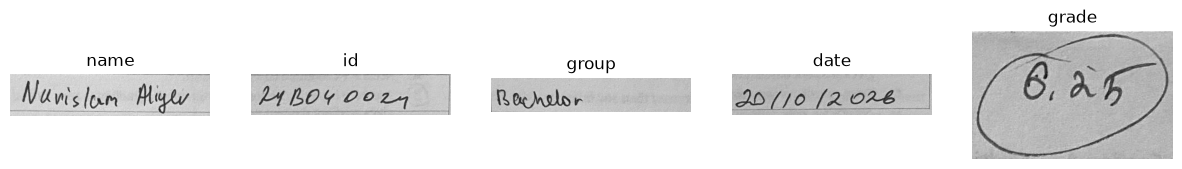

In [2]:
import re
import cv2

page = cv2.imread("midterm.jpg", cv2.IMREAD_GRAYSCALE)
print(page.shape)

# printed text on the page, typed by hand and used as ground truth (handwriting is checked by eye)
TRUTH = """Kazakh-British Technical University School of IT and Engineering
CSCI1409 Deep Learning Fall 2026-2027 Midterm Examination
Week 8 attestation Covers Weeks 1-7 40 questions + 1 bonus 10 points 120 minutes
Full name Student ID Group Date Instructions
Section A (Questions 1-10): multiple choice, 0.15 points each. Circle one letter for each question.
Section B (Questions 11-20): calculations, 0.35 points each. Show your working in the box a correct
method earns partial credit even if the final number is wrong. Round to 3 decimal places; ln is the natural logarithm.
Section C (Questions 21-40): open questions, 0.25 points each. Answer concisely in the lined space. Bullet
points, equations and corrected code are acceptable; there is no minimum length.
Bonus (Question 41): optional, +0.25 points on top of the 10-point total (maximum score 10.25).
Short, precise answers can earn full marks. If you get stuck on a question, move on and come back to it later.
Closed book. A non-programmable calculator is allowed. Phones, notes, laptops, smartwatches and AI tools
are not allowed. Academic integrity
Copying, using unauthorised materials or devices, or communicating with other students during the exam is a
violation of KBTU academic policy and will be reported. All answers must be your own work.
For instructor use Section Questions Points Score A Multiple choice 1-10 1.50 B Calculations 11-20 3.50
C Open questions 21-40 5.00 Total 40 10.00 Bonus (optional) 41 +0.25"""


def norm(text):
    """Lower case and drop punctuation, so scoring looks at the words themselves."""
    return re.sub(r"[^\w\s.+-]", "", text.lower().replace("–", "-").replace("—", " "))


def score(text):
    return word_acc(norm(text), norm(TRUTH))


def adaptive(img):
    return cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 41, 15)


def clahe(img):
    return cv2.createCLAHE(2.0, (8, 8)).apply(img)


versions = {"original": page, "clahe": clahe(page), "adaptive": adaptive(page)}

# handwriting regions, in pixels of the original 1920x2560 photo
crops = {
    "name":  page[745:840, 500:960],
    "id":    page[745:840, 1225:1690],
    "group": page[835:915, 500:960],
    "date":  page[835:930, 1225:1690],
    "grade": page[240:470, 1350:1710],
}

fig, axes = plt.subplots(1, 5, figsize=(15, 2.5))
for ax, (name, crop) in zip(axes, crops.items()):
    ax.imshow(crop, cmap="gray")
    ax.set_title(name)
    ax.axis("off")
plt.show()


## PSM and preprocessing on the photo

In [3]:
print(f"{'version':<12}" + "".join(f"psm{p:<6}" for p in [3, 4, 6, 11]))
for name, img in versions.items():
    row = [score(pytesseract.image_to_string(img, config=f"--psm {p}")) for p in [3, 4, 6, 11]]
    print(f"{name:<12}" + "".join(f"{c:<9.2f}" for c in row))


version     psm3     psm4     psm6     psm11    


original    0.94     0.96     0.97     0.94     


clahe       0.94     0.95     0.91     0.94     


adaptive    0.92     0.91     0.85     0.95     


## Full output

In [4]:
print(pytesseract.image_to_string(page, config="--psm 3"))


Kazakh-British Technical University - School of IT and Engineering

CSC11409 Deep Learning - Fall 2026-2027

Midterm Examination

Week 8 attestation - Covers Weeks 1-7 - 40 questions + 1 bonus: 10 points - 120 minutes

Full pane e Nu ms lem Myey
| Group | fe Ce rte ir
Instructions

Student ID Z ROY 0 0 = ;

|20//0 (RZ O26

|
|
|
|

Section A (Questions 1-10): multiple choice, 0.15 points each. Circle one letter for each question.
Section B (Questions 11-20): calculations, 0.35 points each. Show your working in the box — a correct

method earns partial credit even if the final number is wrong. Round to 3 decimal places; In is the natural

logarithm.

Section C (Questions 21-40): open questions, 0.25 points each. Answer concisely in the lined space. Bullet

points, equations and corrected code are acceptable; there is no minimum length.

later.

are not allowed.

Academic integrity

Bonus (Question 41): optional, +0.25 points on top of the 10-point total (maximum score 10.25).

Short, pr

## Word boxes
Green is confidence above 80, red is below.

275 words, mean confidence 86.6, below 80: 41


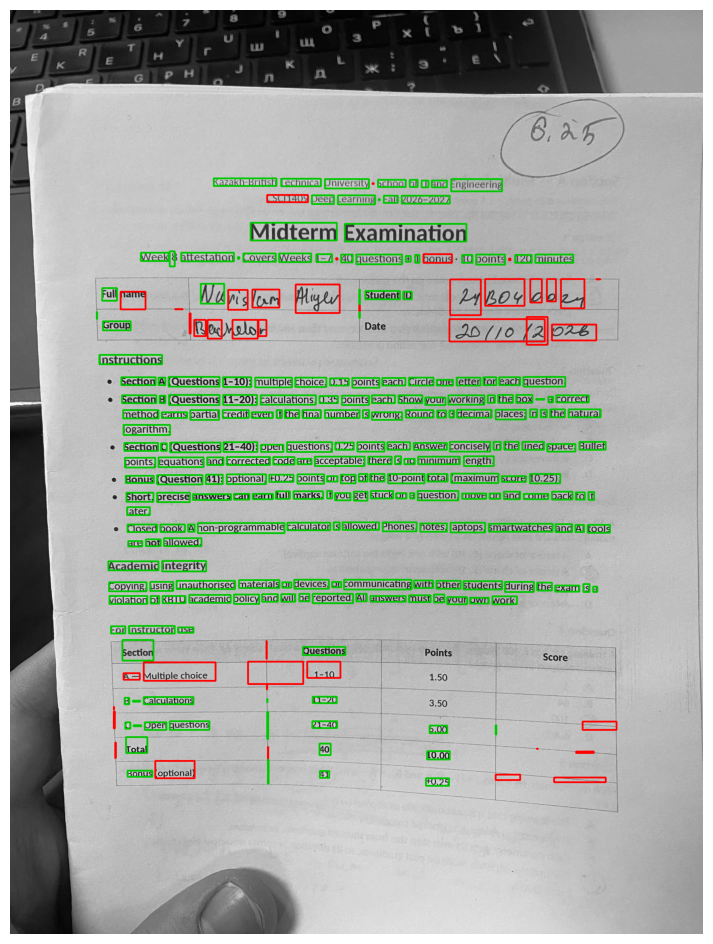

In [5]:
data = pytesseract.image_to_data(page, config="--psm 3", output_type=pytesseract.Output.DICT)
canvas = cv2.cvtColor(page, cv2.COLOR_GRAY2RGB)
confs = []
for i, word in enumerate(data["text"]):
    if word.strip():
        x, y, w, h, conf = data["left"][i], data["top"][i], data["width"][i], data["height"][i], float(data["conf"][i])
        confs.append(conf)
        cv2.rectangle(canvas, (x, y), (x + w, y + h), (0, 200, 0) if conf > 80 else (255, 0, 0), 3)

print(f"{len(confs)} words, mean confidence {np.mean(confs):.1f}, below 80: {sum(c <= 80 for c in confs)}")
plt.figure(figsize=(9, 12))
plt.imshow(canvas)
plt.axis("off")
plt.show()


## Handwriting
Each field is cropped, enlarged and read as a single line.

In [6]:
for name, crop in crops.items():
    big = cv2.resize(crop, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
    print(f"{name:<7}", repr(pytesseract.image_to_string(big, config="--psm 7").strip()))


name    'Navision Miger'
id      ''
group   'Rec nebo r'


date    '2D (Jo (ZOE'
grade   ''
